In [ ]:
# Quick fix cell - run this if any classes are missing
import importlib
import sys

# Reload all modules
if 'RealisticHealthcareIoTEnv' in dir():
    del RealisticHealthcareIoTEnv
if 'TLS13MessageSimulator' in dir():
    del TLS13MessageSimulator
if 'HybridCertificateGenerator' in dir():
    del HybridCertificateGenerator

print("✅ Environment reset - ready to run the simulation!")

In [ ]:
!pip install stable-baselines3 gym torch pandas numpy matplotlib seaborn scikit-learn pycryptodome
!pip install shimmy>=2.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.6/187.6 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 42.0 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize
import matplotlib.pyplot as plt
from cryptography import x509
from cryptography.hazmat.primitives import hashes, serialization
from cryptography.hazmat.primitives.asymmetric import ec
from cryptography.x509.oid import NameOID
from datetime import datetime, timedelta, timezone
import json
import base64
import gym
from gym import spaces
import datetime as dt
import hashlib

# =============================================================================
# PQC / Hybrid / Classical Algorithm Database
# =============================================================================
pqc_algorithms_db = [
    {"id": 0, "name": "dilithium3", "param_set": "L3", "sig_size_bytes": 3293, "verify_time_ms": 0.35, "energy_cost": 0.70, "security_level": 192, "category": "lattice", "key_size_bytes": 1952},
    {"id": 1, "name": "dilithium2", "param_set": "L2", "sig_size_bytes": 2420, "verify_time_ms": 0.22, "energy_cost": 0.50, "security_level": 128, "category": "lattice", "key_size_bytes": 1184},
    {"id": 2, "name": "sphincs_shake_128", "param_set": "small", "sig_size_bytes": 7856, "verify_time_ms": 0.15, "energy_cost": 0.60, "security_level": 128, "category": "hash", "key_size_bytes": 32},
    {"id": 3, "name": "sphincs_sha256", "param_set": "small", "sig_size_bytes": 7856, "verify_time_ms": 0.18, "energy_cost": 0.65, "security_level": 128, "category": "hash", "key_size_bytes": 32},
    {"id": 4, "name": "hybrid_ecdsa_dilithium3", "param_set": "composite", "sig_size_bytes": 3293 + 64, "verify_time_ms": 0.40, "energy_cost": 0.80, "security_level": 256, "category": "hybrid", "key_size_bytes": 1952 + 64},
    {"id": 5, "name": "hybrid_ecdsa_dilithium2", "param_set": "composite", "sig_size_bytes": 2420 + 64, "verify_time_ms": 0.27, "energy_cost": 0.60, "security_level": 192, "category": "hybrid", "key_size_bytes": 1184 + 64},
    {"id": 6, "name": "ecdsa_secp256r1_sha256", "param_set": "P256", "sig_size_bytes": 64, "verify_time_ms": 0.08, "energy_cost": 0.20, "security_level": 128, "category": "classical", "key_size_bytes": 64},
    {"id": 7, "name": "force_reauthentication", "param_set": "security", "sig_size_bytes": 0, "verify_time_ms": 0.50, "energy_cost": 1.00, "security_level": 256, "category": "control", "key_size_bytes": 0},
]

df_pqc = pd.DataFrame(pqc_algorithms_db)
print("✅ Core components and PQC database loaded successfully!")
print(df_pqc[["id", "name", "category", "param_set", "security_level", "verify_time_ms", "energy_cost"]])

✅ Core components and PQC database loaded successfully!
   id                     name   category  param_set  security_level  \
0   0               dilithium3    lattice         L3             192   
1   1               dilithium2    lattice         L2             128   
2   2        sphincs_shake_128       hash      small             128   
3   3           sphincs_sha256       hash      small             128   
4   4  hybrid_ecdsa_dilithium3     hybrid  composite             256   
5   5  hybrid_ecdsa_dilithium2     hybrid  composite             192   
6   6   ecdsa_secp256r1_sha256  classical       P256             128   
7   7   force_reauthentication    control   security             256   

   verify_time_ms  energy_cost  
0            0.35         0.70  
1            0.22         0.50  
2            0.15         0.60  
3            0.18         0.65  
4            0.40         0.80  
5            0.27         0.60  
6            0.08         0.20  
7            0.50         1.00 

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# =============================================================================
# 2. TLS 1.3 Message Simulator
# =============================================================================
class TLS13MessageSimulator:
    """Simulates realistic TLS 1.3 handshake messages with PQC extensions."""

    TLS_CIPHER_SUITES = {
        0x1301: "TLS_AES_128_GCM_SHA256",
        0x1302: "TLS_AES_256_GCM_SHA384",
        0x1303: "TLS_CHACHA20_POLY1305_SHA256",
        0xFE00: "TLS_DILITHIUM3_AES_256_GCM_SHA384",
        0xFE01: "TLS_SPHINCS_SHAKE128_AES_128_GCM_SHA256",
        0xFE02: "TLS_HYBRID_ECDHE_DILITHIUM3_AES_256_GCM_SHA384",
    }

    SIGNATURE_ALGORITHMS = {
        0x0403: "ecdsa_secp256r1_sha256",
        0x0804: "rsa_pss_rsae_sha256",
        0xFE03: "dilithium3",
        0xFE04: "sphincs_shake_128",
        0xFE05: "hybrid_ecdsa_dilithium3",
        0xFE06: "dilithium2",
        0xFE07: "sphincs_sha256",
        0xFE08: "hybrid_ecdsa_dilithium2",
    }

    ALGORITHM_TO_CIPHER_SUITE = {
        "ecdsa_secp256r1_sha256": 0x1301,
        "dilithium3": 0xFE00,
        "sphincs_shake_128": 0xFE01,
        "hybrid_ecdsa_dilithium3": 0xFE02,
        "dilithium2": 0xFE00,
        "sphincs_sha256": 0xFE01,
        "hybrid_ecdsa_dilithium2": 0xFE02,
        "force_reauthentication": 0x1301,
    }

    ALGORITHM_TO_SIGNATURE_ID = {
        "ecdsa_secp256r1_sha256": 0x0403,
        "dilithium3": 0xFE03,
        "sphincs_shake_128": 0xFE04,
        "hybrid_ecdsa_dilithium3": 0xFE05,
        "dilithium2": 0xFE06,
        "sphincs_sha256": 0xFE07,
        "hybrid_ecdsa_dilithium2": 0xFE08,
        "force_reauthentication": 0x0403,
    }

    @staticmethod
    def _normalize_supported_algorithms(supported_algorithms):
        if isinstance(supported_algorithms, dict):
            return list(supported_algorithms.keys()), list(supported_algorithms.values())
        if isinstance(supported_algorithms, list):
            cipher_suites = []
            sig_algs = []
            for algo in supported_algorithms:
                if algo in TLS13MessageSimulator.ALGORITHM_TO_CIPHER_SUITE:
                    cipher_suites.append(TLS13MessageSimulator.ALGORITHM_TO_CIPHER_SUITE[algo])
                sig_algs.append(algo)
            return cipher_suites, sig_algs
        raise TypeError("supported_algorithms must be dict or list")

    @staticmethod
    def create_client_hello(device_info, supported_algorithms):
        cipher_suites, sig_algs = TLS13MessageSimulator._normalize_supported_algorithms(supported_algorithms)
        return {
            "msg_type": "client_hello",
            "version": "TLS 1.3",
            "random": base64.b64encode(np.random.bytes(32)).decode(),
            "legacy_session_id": "",
            "cipher_suites": cipher_suites,
            "legacy_compression_methods": ["null"],
            "extensions": {
                "supported_versions": ["TLS 1.3"],
                "supported_groups": ["x25519", "secp256r1"],
                "key_share": {"group": "x25519", "key_exchange": base64.b64encode(np.random.bytes(32)).decode()},
                "signature_algorithms": sig_algs,
                "device_info_extension": {
                    "type": 0xFF00,
                    "data": {
                        "battery_level": device_info["battery_level"],
                        "cpu_utilization": device_info["cpu_utilization"],
                        "device_type": device_info["device_type"],
                        "data_criticality": device_info["data_criticality"],
                        "available_memory": device_info["available_memory"],
                        "network_latency": device_info["network_latency"],
                        "device_id": device_info.get("device_id", "unknown"),
                    },
                },
            },
        }

    @staticmethod
    def create_server_hello(chosen_algorithm, hybrid_certificate):
        cipher_suite = TLS13MessageSimulator.ALGORITHM_TO_CIPHER_SUITE.get(chosen_algorithm, 0x1301)
        return {
            "msg_type": "server_hello",
            "version": "TLS 1.3",
            "random": base64.b64encode(np.random.bytes(32)).decode(),
            "legacy_session_id": "",
            "cipher_suite": cipher_suite,
            "extensions": {
                "supported_versions": "TLS 1.3",
                "key_share": {"group": "x25519", "key_exchange": base64.b64encode(np.random.bytes(32)).decode()},
                "selected_signature_algorithm": hybrid_certificate["signature_algorithm"],
            },
            "certificate": hybrid_certificate,
        }

    @staticmethod
    def calculate_handshake_metrics(client_hello, server_hello, chosen_algorithm):
        algorithm_performance = {
            "dilithium3": {"sign_time_ms": 2.1, "verify_time_ms": 0.35, "energy": 0.70, "sig_size_bytes": 3293},
            "dilithium2": {"sign_time_ms": 1.4, "verify_time_ms": 0.22, "energy": 0.50, "sig_size_bytes": 2420},
            "sphincs_shake_128": {"sign_time_ms": 12.5, "verify_time_ms": 0.15, "energy": 0.60, "sig_size_bytes": 7856},
            "sphincs_sha256": {"sign_time_ms": 12.8, "verify_time_ms": 0.18, "energy": 0.65, "sig_size_bytes": 7856},
            "hybrid_ecdsa_dilithium3": {"sign_time_ms": 2.3, "verify_time_ms": 0.40, "energy": 0.80, "sig_size_bytes": 3293 + 64},
            "hybrid_ecdsa_dilithium2": {"sign_time_ms": 1.7, "verify_time_ms": 0.27, "energy": 0.60, "sig_size_bytes": 2420 + 64},
            "ecdsa_secp256r1_sha256": {"sign_time_ms": 0.8, "verify_time_ms": 0.08, "energy": 0.20, "sig_size_bytes": 64},
            "force_reauthentication": {"sign_time_ms": 0.5, "verify_time_ms": 0.50, "energy": 1.00, "sig_size_bytes": 0},
        }
        algo_info = algorithm_performance.get(chosen_algorithm, algorithm_performance["dilithium2"])
        network_latency = client_hello["extensions"]["device_info_extension"]["data"]["network_latency"]
        total_time = network_latency + algo_info["verify_time_ms"] * 1000.0 + float(np.random.normal(5.0, 1.0))
        battery_level = client_hello["extensions"]["device_info_extension"]["data"]["battery_level"]
        energy_consumed = algo_info["energy"] * (1.0 - battery_level) * 0.1
        return {
            "handshake_latency_ms": max(0.0, total_time),
            "energy_consumed": max(0.0, energy_consumed),
            "signature_size_bytes": algo_info["sig_size_bytes"],
            "success": True,
        }


# =============================================================================
# 3. Hybrid Certificate Implementation
# =============================================================================
class HybridCertificateGenerator:
    """Generates realistic hybrid X.509-like certificates with PQC support."""

    def generate_hybrid_certificate(self, device_info, signature_algorithm="dilithium3"):
        pq_key_sizes = {
            "dilithium3": 1952, "dilithium2": 1184, "sphincs_shake_128": 32,
            "sphincs_sha256": 32, "hybrid_ecdsa_dilithium3": 1952 + 64,
            "hybrid_ecdsa_dilithium2": 1184 + 64, "ecdsa_secp256r1_sha256": 64,
            "force_reauthentication": 0,
        }
        param_set_map = {
            "dilithium3": "L3", "dilithium2": "L2", "sphincs_shake_128": "small",
            "sphincs_sha256": "small", "hybrid_ecdsa_dilithium3": "composite",
            "hybrid_ecdsa_dilithium2": "composite", "ecdsa_secp256r1_sha256": "P256",
            "force_reauthentication": "control",
        }
        pq_key_size = pq_key_sizes.get(signature_algorithm, 1184)
        now_utc = dt.datetime.now(dt.timezone.utc)
        return {
            "version": "v3",
            "serial_number": int.from_bytes(np.random.bytes(8), byteorder="big"),
            "subject": f"CN={device_info['device_type']}_{device_info['device_id']}, O=HealthcareIoT, C=US",
            "issuer": "CN=HealthcareIoT CA, O=HealthcareIoT, C=US",
            "validity": {
                "not_before": now_utc.isoformat(),
                "not_after": (now_utc + dt.timedelta(days=365)).isoformat(),
            },
            "classical_public_key": {"algorithm": "ECDSA_P256", "public_key": base64.b64encode(np.random.bytes(64)).decode()},
            "post_quantum_public_key": {
                "algorithm": signature_algorithm,
                "parameter_set": param_set_map.get(signature_algorithm, "L2"),
                "public_key": base64.b64encode(np.random.bytes(max(1, pq_key_size))).decode(),
                "key_size": pq_key_size,
            },
            "extensions": {
                "key_usage": ["digital_signature", "key_encipherment"],
                "extended_key_usage": ["client_auth", "server_auth"],
                "subject_alt_name": f"DNS:{device_info['device_type']}.healthcare.iot",
                "healthcare_device_metadata": {
                    "device_type": device_info["device_type"],
                    "data_criticality": device_info["data_criticality"],
                    "max_auth_frequency": device_info.get("max_auth_frequency", 10),
                    "allowed_algorithms": ["dilithium3", "dilithium2", "sphincs_shake_128", "sphincs_sha256", "hybrid_ecdsa_dilithium3", "hybrid_ecdsa_dilithium2", "ecdsa_secp256r1_sha256"],
                },
            },
            "signature_algorithm": signature_algorithm,
            "signature": base64.b64encode(np.random.bytes(512)).decode(),
            "_tampered": False,
            "_forged": False,
        }

    def verify_certificate(self, certificate, signature_algorithm):
        issuer_ok = certificate.get("issuer") == "CN=HealthcareIoT CA, O=HealthcareIoT, C=US"
        signature_present = isinstance(certificate.get("signature"), str) and len(certificate.get("signature", "")) > 0
        tampered = certificate.get("_tampered", False)
        forged = certificate.get("_forged", False)
        certificate_valid = issuer_ok and signature_present and not tampered and not forged
        verification_time_map = {
            "dilithium3": 2.5, "dilithium2": 1.8, "sphincs_shake_128": 2.2,
            "sphincs_sha256": 2.3, "hybrid_ecdsa_dilithium3": 2.8,
            "hybrid_ecdsa_dilithium2": 2.1, "ecdsa_secp256r1_sha256": 1.0,
            "force_reauthentication": 0.5,
        }
        return {
            "classical_verification": issuer_ok,
            "pqc_verification": not tampered,
            "certificate_valid": certificate_valid,
            "verification_time_ms": verification_time_map.get(signature_algorithm, 1.8),
        }

print("✅ TLS Simulator and Certificate Generator loaded successfully!")

✅ TLS Simulator and Certificate Generator loaded successfully!


In [ ]:
# =============================================================================
# 4. Enhanced Healthcare IoT Environment with Real TLS
#    (FINAL VERSION - 17 FEATURES)
# =============================================================================

import datetime as dt
import numpy as np
import gym
from gym import spaces
import hashlib
import base64

# =============================================================================
# AttackSimulator
# =============================================================================

class AttackSimulator:
    """Attack simulation for TLS handshake experiments."""

    def __init__(self, attack_probability=0.07):
        self.attack_probability = float(attack_probability)
        self.attack_detected = False
        self.downgrade_detected = False
        self.replay_detected = False
        self.forgery_detected = False
        self.tampering_detected = False
        self.attack_log = []
        self.message_history = []

    def reset_flags(self):
        self.attack_detected = False
        self.downgrade_detected = False
        self.replay_detected = False
        self.forgery_detected = False
        self.tampering_detected = False

    def should_launch_attack(self):
        return np.random.random() < self.attack_probability

    def select_attack_type(self):
        return np.random.choice(["mitm", "replay", "forgery", "tampering", "downgrade"])

    def launch_attack(self, message, attack_type=None):
        self.reset_flags()
        if attack_type is None:
            attack_type = self.select_attack_type()
        if attack_type == "mitm":
            return self.simulate_mitm_attack(message), attack_type
        if attack_type == "replay":
            return self.simulate_replay_attack(message), attack_type
        if attack_type == "forgery":
            return self.simulate_certificate_forgery(message), attack_type
        if attack_type == "tampering":
            return self.simulate_signature_tampering(message), attack_type
        if attack_type == "downgrade":
            return self.simulate_downgrade_message(message), attack_type
        return message, "none"

    def simulate_mitm_attack(self, client_hello):
        modified = dict(client_hello)
        modified["extensions"] = dict(client_hello.get("extensions", {}))
        if "cipher_suites" in modified:
            classical_suites = [0x1301, 0x1302, 0x1303]
            original_len = len(modified["cipher_suites"])
            modified["cipher_suites"] = [
                suite for suite in modified["cipher_suites"] if suite in classical_suites
            ]
            if len(modified["cipher_suites"]) < original_len:
                self.attack_detected = True
            self.attack_log.append({
                "type": "mitm",
                "description": "Removed PQ/hybrid cipher suites from negotiation",
                "detected": self.attack_detected
            })
        return modified

    def simulate_replay_attack(self, message):
        modified = dict(message)
        modified["replay_marker"] = True
        msg_id = message.get("legacy_session_id", "")
        for old_msg in self.message_history[-5:]:
            if old_msg.get("legacy_session_id") == msg_id:
                self.replay_detected = True
                self.attack_detected = True
        self.message_history.append({"legacy_session_id": msg_id})
        self.attack_log.append({
            "type": "replay",
            "description": "Reused previous message context",
            "detected": self.replay_detected
        })
        return modified

    def simulate_certificate_forgery(self, original_cert):
        forged_cert = dict(original_cert)
        if "issuer" in forged_cert:
            forged_cert["issuer"] = "CN=Fake_CA, O=Attacker"
            forged_cert["_forged"] = True
            self.forgery_detected = True
            self.attack_detected = True
        return forged_cert

    def simulate_signature_tampering(self, certificate):
        tampered_cert = dict(certificate)
        if "signature" in tampered_cert:
            tampered_cert["signature"] = base64.b64encode(np.random.bytes(64)).decode()
            tampered_cert["_tampered"] = True
            self.tampering_detected = True
            self.attack_detected = True
        return tampered_cert

    def simulate_downgrade_attack(self, supported_cipher_suites):
        pq_cipher_suites = [0xFE00, 0xFE01, 0xFE02]
        original_len = len(supported_cipher_suites)
        downgraded = [
            suite for suite in supported_cipher_suites if suite not in pq_cipher_suites
        ]
        self.downgrade_detected = len(downgraded) < original_len
        if self.downgrade_detected:
            self.attack_detected = True
        return downgraded

    def simulate_downgrade_message(self, client_hello):
        modified = dict(client_hello)
        if "cipher_suites" in modified:
            modified["cipher_suites"] = self.simulate_downgrade_attack(
                modified["cipher_suites"]
            )
            self.attack_log.append({
                "type": "downgrade",
                "description": "Removed PQ/hybrid cipher suites to force classical negotiation",
                "detected": self.downgrade_detected
            })
        return modified

    def get_attack_statistics(self):
        total_attacks = len(self.attack_log)
        if total_attacks == 0:
            return {"total_attacks": 0, "detected_attacks": 0, "detection_rate": 0}
        detected = sum(1 for a in self.attack_log if a.get("detected", False))
        return {
            "total_attacks": total_attacks,
            "detected_attacks": detected,
            "detection_rate": (detected / total_attacks * 100)
        }


class DowngradeMitigation:
    """Mechanism to detect downgrade attacks."""

    def __init__(self):
        self.transcript_hash = None
        self.original_algorithms = []

    def create_handshake_transcript(self, client_hello, server_hello, certificate):
        if "extensions" in client_hello and "signature_algorithms" in client_hello["extensions"]:
            self.original_algorithms = client_hello["extensions"]["signature_algorithms"]
        transcript_data = {
            "client_hello": {
                "random": client_hello.get("random"),
                "cipher_suites": client_hello.get("cipher_suites"),
                "extensions": client_hello.get("extensions", {})
            },
            "server_hello": {
                "random": server_hello.get("random"),
                "cipher_suite": server_hello.get("cipher_suite"),
                "extensions": server_hello.get("extensions", {})
            },
            "certificate": {
                "subject": certificate.get("subject"),
                "issuer": certificate.get("issuer"),
                "signature_algorithm": certificate.get("signature_algorithm")
            },
            "timestamp": dt.datetime.now(dt.timezone.utc).isoformat(),
        }
        transcript_string = str(transcript_data).encode("utf-8")
        self.transcript_hash = hashlib.sha256(transcript_string).hexdigest()
        return {
            "transcript": transcript_data,
            "hash": self.transcript_hash,
            "original_algorithms": self.original_algorithms
        }

    def verify_downgrade_attempt(self, original_cipher_suites, selected_cipher_suite, transcript_hash):
        if selected_cipher_suite not in original_cipher_suites:
            return {
                "downgrade_attempted": True,
                "reason": "Selected cipher suite not in original supported list",
            }
        if transcript_hash != self.transcript_hash:
            return {
                "downgrade_attempted": True,
                "reason": "Transcript hash mismatch",
            }
        return {"downgrade_attempted": False, "verified": True}

    def verify_handshake(self, server_hello, transcript_hash):
        result = {"downgrade_attempted": False, "verified": False, "reasons": []}
        if "extensions" in server_hello:
            selected_algo = server_hello["extensions"].get("selected_signature_algorithm")
            if selected_algo and selected_algo not in self.original_algorithms:
                result["downgrade_attempted"] = True
                result["reasons"].append(f"Algorithm {selected_algo} not in original list")
        if transcript_hash != self.transcript_hash:
            result["downgrade_attempted"] = True
            result["reasons"].append("Transcript hash mismatch")
        if server_hello.get("version") != "TLS 1.3":
            result["downgrade_attempted"] = True
            result["reasons"].append(f"Downgraded to {server_hello.get('version')}")
        result["verified"] = not result["downgrade_attempted"]
        return result


# =============================================================================
# RealisticHealthcareIoTEnv - FINAL VERSION (17 FEATURES)
# =============================================================================

class RealisticHealthcareIoTEnv(gym.Env):
    """
    FINAL VERSION - 17 features (removed ONLY attack_value indicator)
    """

    def __init__(self, num_devices=15):
        super().__init__()
        self.num_devices = num_devices
        self.current_step = 0
        self.max_steps = 500
        self.action_space = spaces.Discrete(8)

        # 17 features (removed attack_value from original 18)
        self.observation_space = spaces.Box(
            low=0.0, high=1.0, shape=(17,), dtype=np.float32
        )

        self.tls_simulator = TLS13MessageSimulator()
        self.cert_generator = HybridCertificateGenerator()
        self.attack_simulator = AttackSimulator(attack_probability=0.07)
        self.downgrade_mitigation = DowngradeMitigation()

        self.attack_metrics = {
            "mitm_attempts": 0,
            "replay_attempts": 0,
            "forgery_attempts": 0,
            "tampering_attempts": 0,
            "downgrade_attempts": 0,
            "attacks_detected": 0,
        }

        self.device_states = self._initialize_healthcare_devices()
        self.performance_history = []
        self.previous_handshake = None
        self.current_attack_type = "none"
        self.prev_dist = None
        self.safety_violations = 0
        self.shielded_actions = 0

        self.algorithm_mapping = {
            0: "dilithium3",
            1: "dilithium2",
            2: "sphincs_shake_128",
            3: "sphincs_sha256",
            4: "hybrid_ecdsa_dilithium3",
            5: "hybrid_ecdsa_dilithium2",
            6: "ecdsa_secp256r1_sha256",
            7: "force_reauthentication",
        }

    def _initialize_healthcare_devices(self):
        devices = []
        profiles = [
            {"type": "critical_high_power", "count": 3, "profile": 0, "criticality": 2},
            {"type": "critical_medium_power", "count": 5, "profile": 1, "criticality": 2},
            {"type": "critical_low_power", "count": 3, "profile": 1, "criticality": 2},
            {"type": "non_critical", "count": 4, "profile": 2, "criticality": 0},
        ]
        device_id = 0
        for p in profiles:
            for _ in range(p["count"]):
                devices.append({
                    "device_id": f"med_device_{device_id:04d}",
                    "device_type": p["type"],
                    "profile": p["profile"],
                    "battery_level": np.random.uniform(0.3, 1.0),
                    "cpu_utilization": np.random.uniform(0.1, 0.6),
                    "network_latency": np.random.uniform(10, 150),
                    "packet_loss": np.random.uniform(0.0, 0.05),
                    "signal_strength": np.random.uniform(0.6, 1.0),
                    "data_criticality": p["criticality"],
                    "transmission_frequency": np.random.uniform(0.1, 100),
                    "data_volume": np.random.uniform(0.1, 1.0),
                    "threat_level": np.random.uniform(0.0, 0.2),
                    "auth_failures": 0,
                    "last_auth_time": 0,
                    "current_algorithm": 6,
                    "emergency_mode": 0,
                    "available_memory": np.random.uniform(50, 500),
                    "certificate": None,
                })
                device_id += 1
        return devices

    def _get_state(self, device_idx):
        """17 features - removed ONLY attack_value."""
        d = self.device_states[device_idx]
        algo = self.algorithm_mapping[d["current_algorithm"]]

        lat_n = np.clip(d["network_latency"] / 200.0, 0.0, 1.0)
        pl_n = np.clip(d["packet_loss"] / 0.05, 0.0, 1.0)
        congestion = np.clip(0.7 * lat_n + 0.3 * pl_n, 0.0, 1.0)
        algo_cost = self._get_algorithm_cost(algo)
        bw_use = self._get_bandwidth_usage(algo)
        energy_feature = np.clip(algo_cost * (0.5 + d["cpu_utilization"]), 0.0, 1.0)
        time_since_auth = np.clip(d["last_auth_time"] / 3600.0, 0.0, 1.0)

        state = np.array([
            d["profile"] / 2.0,
            d["battery_level"],
            d["cpu_utilization"],
            lat_n,
            pl_n,
            d["signal_strength"],
            d["data_criticality"] / 2.0,
            np.clip(d["transmission_frequency"] / 100.0, 0.0, 1.0),
            d["data_volume"],
            d["threat_level"],
            min(d["auth_failures"] / 5.0, 1.0),
            time_since_auth,
            algo_cost,
            bw_use,
            energy_feature,
            congestion,
            float(d["emergency_mode"]),
        ], dtype=np.float32)
        return state

    def step(self, action):
        action = int(action)
        idx = self.current_step % len(self.device_states)
        device = self.device_states[idx]

        if not self._is_action_safe(action, device):
            self.shielded_actions += 1
            action = self._get_fallback_action(device)
            self.safety_violations += 1

        success, metrics = self._perform_realistic_tls_handshake(idx, action)
        self._update_device_state(device, action, success, metrics)

        state = self._get_state(idx)
        reward = self._calculate_reward(state, action, success, metrics, device)
        reward = float(np.clip(reward, -3.0, 3.0))

        device["last_auth_time"] += 1
        self.current_step += 1

        self.performance_history.append({
            "step": self.current_step,
            "device": idx,
            "device_id": device["device_id"],
            "device_type": device["device_type"],
            "action": action,
            "algorithm": self.algorithm_mapping[action],
            "reward": reward,
            "success": success,
            "battery": device["battery_level"],
            "latency": metrics["handshake_latency_ms"],
            "energy_consumed": metrics["energy_consumed"],
            "criticality": device["data_criticality"],
            "attack_type": metrics.get("attack_type", None),
            "attack_detected": metrics.get("attack_detected", False),
        })

        done = self.current_step >= self.max_steps or self._check_emergency_condition()

        info = {
            "success": success,
            "latency_ms": metrics["handshake_latency_ms"],
            "battery_level": device["battery_level"],
            "algorithm": self.algorithm_mapping[action],
            "device_type": device["device_type"],
            "emergency_mode": device.get("emergency_mode", False),
            "attack_detected": metrics.get("attack_detected", False),
            "attack_type": metrics.get("attack_type", None),
            "safety_violations": self.safety_violations,
        }

        return state, reward, done, info

    def _update_device_state(self, device, action, success, metrics):
        device["current_algorithm"] = action
        device["battery_level"] = max(0.0, device["battery_level"] - metrics["energy_consumed"])
        if success or self.algorithm_mapping[action] == "force_reauthentication":
            device["last_auth_time"] = 0
            device["auth_failures"] = max(0, device["auth_failures"] - 1)
        else:
            device["auth_failures"] += 1

    def _calculate_reward(self, state, action, success, metrics, device):
        algo = self.algorithm_mapping[action]

        security_map = {
            "dilithium3": 1.0,
            "dilithium2": 0.8,
            "sphincs_shake_128": 0.8,
            "sphincs_sha256": 0.8,
            "hybrid_ecdsa_dilithium3": 1.0,
            "hybrid_ecdsa_dilithium2": 0.9,
            "ecdsa_secp256r1_sha256": 0.5,
            "force_reauthentication": -0.3,
        }
        security_reward = security_map.get(algo, 0.5)
        crit_mult = {0: 0.6, 1: 1.0, 2: 1.4}[device["data_criticality"]]
        security_reward *= crit_mult

        safety_cost = 0.0
        energy_cost = self._get_algorithm_cost(algo)
        if device["battery_level"] < 0.2 and energy_cost > 0.5:
            safety_cost += 1.0
        if device["data_criticality"] == 2 and metrics["handshake_latency_ms"] > 400:
            safety_cost += 1.5
        if device["data_criticality"] == 2 and algo == "ecdsa_secp256r1_sha256":
            safety_cost += 3.0

        energy_efficiency = {
            "dilithium3": 0.3, "dilithium2": 0.5,
            "sphincs_shake_128": 0.4, "sphincs_sha256": 0.4,
            "hybrid_ecdsa_dilithium3": 0.2, "hybrid_ecdsa_dilithium2": 0.4,
            "ecdsa_secp256r1_sha256": 0.8, "force_reauthentication": 0.1,
        }
        low_batt_importance = 1.0 + (1.0 - device["battery_level"])
        energy_bonus = energy_efficiency.get(algo, 0.5) * low_batt_importance

        latency_penalty = np.clip(metrics["handshake_latency_ms"] / 500.0, 0.0, 2.0)
        success_bonus = 2.5 if success else -1.2

        attack_penalty = 0.0
        if metrics.get("attack_type") is not None:
            if metrics.get("attack_detected", False):
                attack_penalty = 1.5
            else:
                attack_penalty = -2.5

        battery_bonus = 0.0
        if device["battery_level"] < 0.2:
            if algo in ["ecdsa_secp256r1_sha256", "dilithium2", "sphincs_shake_128"]:
                battery_bonus = 0.5
            else:
                battery_bonus = -0.5

        distance_reward = 0.0
        if self.prev_dist is not None:
            current_dist = device["battery_level"]
            distance_reward = (self.prev_dist - current_dist) * 0.1
            self.prev_dist = current_dist
        else:
            self.prev_dist = device["battery_level"]

        diversity_bonus = 0.0
        rare_algorithms = ["sphincs_shake_128", "sphincs_sha256", "hybrid_ecdsa_dilithium3",
                          "hybrid_ecdsa_dilithium2", "dilithium3", "dilithium2",
                          "ecdsa_secp256r1_sha256"]
        if algo in rare_algorithms:
            if algo in ["sphincs_shake_128", "hybrid_ecdsa_dilithium3"]:
                diversity_bonus = 0.5
            else:
                diversity_bonus = 0.3

        total_reward = (
            0.6 * security_reward
            - 0.2 * safety_cost
            - 0.25 * latency_penalty
            + 0.25 * energy_bonus
            + 1.0 * success_bonus
            + attack_penalty
            + 0.5 * battery_bonus
            + distance_reward
            + diversity_bonus
        )
        return np.clip(total_reward, -3.0, 3.0)

    def _perform_realistic_tls_handshake(self, device_idx, action_idx):
        device = self.device_states[device_idx]
        chosen_algorithm = self.algorithm_mapping[action_idx]

        if device["certificate"] is None:
            device["certificate"] = self.cert_generator.generate_hybrid_certificate(
                device, chosen_algorithm
            )

        supported_algorithms = [
            "dilithium3", "dilithium2", "sphincs_shake_128",
            "sphincs_sha256", "hybrid_ecdsa_dilithium3",
            "hybrid_ecdsa_dilithium2", "ecdsa_secp256r1_sha256",
        ]

        client_hello = self.tls_simulator.create_client_hello(
            device_info={
                "battery_level": device["battery_level"],
                "cpu_utilization": device["cpu_utilization"],
                "device_type": device["device_type"],
                "data_criticality": device["data_criticality"],
                "available_memory": device["available_memory"],
                "network_latency": device["network_latency"],
                "device_id": device["device_id"],
            },
            supported_algorithms=supported_algorithms,
        )

        attack_scenario = np.random.choice(
            ["none", "mitm", "replay", "forgery", "tampering", "downgrade"],
            p=[0.93, 0.014, 0.014, 0.014, 0.014, 0.014],
        )

        self.current_attack_type = attack_scenario
        attack_detected = False
        modified_client_hello = dict(client_hello)
        original_cipher_suites = list(client_hello["cipher_suites"])

        if attack_scenario == "mitm":
            self.attack_metrics["mitm_attempts"] += 1
            modified_client_hello = self.attack_simulator.simulate_mitm_attack(client_hello)
            attack_detected = self.attack_simulator.attack_detected
            if attack_detected:
                self.attack_metrics["attacks_detected"] += 1

        elif attack_scenario == "replay":
            self.attack_metrics["replay_attempts"] += 1
            modified_client_hello = self.attack_simulator.simulate_replay_attack(client_hello)
            attack_detected = self.attack_simulator.replay_detected
            if attack_detected:
                self.attack_metrics["attacks_detected"] += 1

        elif attack_scenario == "forgery":
            self.attack_metrics["forgery_attempts"] += 1
            device["certificate"] = self.attack_simulator.simulate_certificate_forgery(
                device["certificate"]
            )

        elif attack_scenario == "tampering":
            self.attack_metrics["tampering_attempts"] += 1
            device["certificate"] = self.attack_simulator.simulate_signature_tampering(
                device["certificate"]
            )

        elif attack_scenario == "downgrade":
            self.attack_metrics["downgrade_attempts"] += 1
            downgraded = self.attack_simulator.simulate_downgrade_attack(original_cipher_suites)
            modified_client_hello["cipher_suites"] = downgraded
            attack_detected = self.attack_simulator.downgrade_detected
            if attack_detected:
                self.attack_metrics["attacks_detected"] += 1

        server_hello = self.tls_simulator.create_server_hello(
            chosen_algorithm=chosen_algorithm,
            hybrid_certificate=device["certificate"],
        )

        transcript = self.downgrade_mitigation.create_handshake_transcript(
            modified_client_hello, server_hello, device["certificate"]
        )

        if attack_scenario == "downgrade":
            selected_cipher_suite = server_hello["cipher_suite"]
            verify_result = self.downgrade_mitigation.verify_downgrade_attempt(
                list(client_hello["cipher_suites"]),
                selected_cipher_suite,
                transcript["hash"],
            )
            if verify_result.get("downgrade_attempted", False):
                attack_detected = True
                self.attack_metrics["attacks_detected"] += 1

        metrics = self.tls_simulator.calculate_handshake_metrics(
            modified_client_hello, server_hello, chosen_algorithm
        )

        verification = self.cert_generator.verify_certificate(
            device["certificate"], chosen_algorithm
        )

        if attack_scenario in ["forgery", "tampering"]:
            if not verification["certificate_valid"]:
                attack_detected = True
                self.attack_metrics["attacks_detected"] += 1
            else:
                attack_detected = False

        success = (
            verification["certificate_valid"]
            and metrics["handshake_latency_ms"] < 1000
            and np.random.random() > device["packet_loss"]
        )

        if attack_scenario in ["forgery", "tampering"] and attack_detected:
            success = False

        metrics["success"] = success
        metrics["verification_time"] = verification["verification_time_ms"]
        metrics["attack_type"] = attack_scenario if attack_scenario != "none" else None
        metrics["attack_detected"] = attack_detected

        self.previous_handshake = {
            "client_hello": client_hello,
            "server_hello": server_hello,
            "timestamp": dt.datetime.now(dt.timezone.utc),
        }

        return success, metrics

    def _is_action_safe(self, action, device):
        algorithm = self.algorithm_mapping[action]

        if device["data_criticality"] == 2 and algorithm == "ecdsa_secp256r1_sha256":
            if device["battery_level"] > 0.1:
                return False
            return True

        if device["battery_level"] < 0.02 and self._get_algorithm_cost(algorithm) > 0.7:
            return False

        if device["emergency_mode"] == 1:
            if algorithm in ["dilithium3", "hybrid_ecdsa_dilithium3", "dilithium2"]:
                return True
            return False

        return True

    def _get_fallback_action(self, device):
        if device["emergency_mode"] == 1:
            return 0
        elif device["data_criticality"] == 2:
            return 0 if device["battery_level"] > 0.3 else 1
        else:
            return 6 if device["battery_level"] < 0.1 else 1

    def _get_algorithm_cost(self, algorithm):
        cost_map = {
            "dilithium3": 0.7, "dilithium2": 0.5,
            "sphincs_shake_128": 0.6, "sphincs_sha256": 0.65,
            "hybrid_ecdsa_dilithium3": 0.8, "hybrid_ecdsa_dilithium2": 0.6,
            "ecdsa_secp256r1_sha256": 0.2, "force_reauthentication": 1.0,
        }
        return cost_map.get(algorithm, 0.5)

    def _get_bandwidth_usage(self, algorithm):
        bandwidth_map = {
            "dilithium3": 0.4, "dilithium2": 0.3,
            "sphincs_shake_128": 0.9, "sphincs_sha256": 0.9,
            "hybrid_ecdsa_dilithium3": 0.45, "hybrid_ecdsa_dilithium2": 0.35,
            "ecdsa_secp256r1_sha256": 0.1, "force_reauthentication": 0.0,
        }
        return bandwidth_map.get(algorithm, 0.5)

    def _check_emergency_condition(self):
        if np.random.random() < 0.002:
            critical_devices = [
                i for i, d in enumerate(self.device_states)
                if d["data_criticality"] == 2
            ]
            if critical_devices:
                affected = np.random.choice(
                    critical_devices,
                    size=min(3, len(critical_devices)),
                    replace=False,
                )
                for idx in affected:
                    self.device_states[idx]["emergency_mode"] = 1
                    self.device_states[idx]["threat_level"] = min(
                        1.0,
                        self.device_states[idx]["threat_level"] + 0.3,
                    )
        return False

    def reset(self):
        self.current_step = 0
        self.device_states = self._initialize_healthcare_devices()
        self.performance_history = []
        self.attack_metrics = {
            "mitm_attempts": 0,
            "replay_attempts": 0,
            "forgery_attempts": 0,
            "tampering_attempts": 0,
            "downgrade_attempts": 0,
            "attacks_detected": 0,
        }
        self.current_attack_type = "none"
        self.prev_dist = None
        self.previous_handshake = None
        self.safety_violations = 0
        self.shielded_actions = 0
        return self._get_state(0)

    def render(self, mode="human"):
        if len(self.performance_history) > 0:
            latest = self.performance_history[-1]
            device = self.device_states[latest["device"]]
            algo = self.algorithm_mapping[latest["action"]]
            print(f"Step: {self.current_step:04d} | Device: {device['device_id']}")
            print(f"  Algorithm: {algo} | Reward: {latest['reward']:7.2f}")
            print(f"  Battery: {device['battery_level']:5.1%} | Crit: {device['data_criticality']}")
            print(f"  Safety Violations: {self.safety_violations}")
            if latest.get("attack_type"):
                print(
                    f"  ⚔️ Attack: {latest['attack_type']} | "
                    f"Detected: {latest.get('attack_detected', False)}"
                )
            print("-" * 50)


print("=" * 80)
print("✅ ENVIRONMENT READY - 17 FEATURES")
print("=" * 80)
print("📌 State: 17 features (attack_value removed)")
print("📌 Attack probability: 7%")
print("=" * 80)

✅ ENVIRONMENT READY - 17 FEATURES
📌 State: 17 features (attack_value removed)
📌 Attack probability: 7%


In [ ]:
# =============================================================================
# 5. Healthcare TLS Analyzer and Simulation Runner
# =============================================================================

class HealthcareTLSAnalyzer:
    """Comprehensive analysis and visualization for healthcare TLS performance"""

    def __init__(self, model, environment):
        self.model = model
        self.env = environment
        self.analysis_results = {}
        self.df_analysis = None

    def run_comprehensive_analysis(self, num_episodes=10):
        print("🏥 Running Comprehensive Healthcare TLS Analysis...")
        all_episode_data = []
        for episode in range(num_episodes):
            print(f"\n📊 Episode {episode + 1}/{num_episodes}")
            obs = self.env.reset()
            episode_data = []
            total_reward = 0
            steps = 0
            done = False
            while not done:
                action, _states = self.model.predict(obs, deterministic=True)
                if isinstance(action, np.ndarray):
                    action_scalar = action.item()
                elif hasattr(action, "__len__") and len(action) > 0:
                    action_scalar = action[0]
                else:
                    action_scalar = int(action)
                obs, reward, done, info = self.env.step(action_scalar)

                if hasattr(self.env, "current_step") and hasattr(self.env, "device_states"):
                    idx = (self.env.current_step - 1) % len(self.env.device_states)
                    device = self.env.device_states[idx]
                else:
                    idx = 0
                    device = {}

                algorithm_name = self.env.algorithm_mapping.get(
                    action_scalar, f"Algorithm_{action_scalar}"
                )

                if hasattr(self.env, "performance_history") and len(self.env.performance_history) > 0:
                    latest_perf = self.env.performance_history[-1]
                    energy_consumed = latest_perf.get(
                        "energy_consumed",
                        self.env._get_algorithm_cost(algorithm_name) * 0.1
                    )
                else:
                    energy_consumed = self.env._get_algorithm_cost(algorithm_name) * 0.1 \
                        if hasattr(self.env, "_get_algorithm_cost") else 0.05

                step_info = {
                    "episode": episode,
                    "step": steps,
                    "reward": reward,
                    "total_reward": total_reward + reward,
                    "algorithm": algorithm_name,
                    "device_type": device.get("device_type", "unknown") if device else "unknown",
                    "criticality": device.get("data_criticality", 0) if device else 0,
                    "battery": device.get("battery_level", 0.5) if device else 0.5,
                    "latency": info.get("latency_ms", 0) if isinstance(info, dict) else 0,
                    "success": info.get("success", False) if isinstance(info, dict) else False,
                    "energy_consumed": energy_consumed,
                    "attack_detected": info.get("attack_detected", False) if isinstance(info, dict) else False,
                    "attack_type": info.get("attack_type", None) if isinstance(info, dict) else None,
                }
                episode_data.append(step_info)
                total_reward += reward
                steps += 1
                if done:
                    break
            self.analysis_results[f"episode_{episode}"] = {
                "total_reward": total_reward,
                "steps": steps,
                "data": episode_data
            }
            all_episode_data.extend(episode_data)
            print(f"   Total Reward: {total_reward:.2f} | Steps: {steps}")
        self.df_analysis = pd.DataFrame(all_episode_data)
        return self.df_analysis

    def visualize_performance(self):
        if self.df_analysis is None:
            print("⚠️ Please run analysis first")
            return

        fig, axes = plt.subplots(2, 4, figsize=(24, 12))
        fig.suptitle("Healthcare IoT Adaptive TLS Performance Analysis", fontsize=16, fontweight="bold")

        if "algorithm" in self.df_analysis.columns and "device_type" in self.df_analysis.columns:
            try:
                algo_device = pd.crosstab(self.df_analysis["algorithm"], self.df_analysis["device_type"])
                if not algo_device.empty:
                    algo_device.plot(kind="bar", ax=axes[0, 0], title="Algorithm Choice by Device Type")
                    axes[0, 0].set_ylabel("Frequency")
                    axes[0, 0].tick_params(axis="x", rotation=45)
            except:
                pass

        if "step" in self.df_analysis.columns and "reward" in self.df_analysis.columns:
            try:
                reward_by_step = self.df_analysis.groupby("step")["reward"].mean()
                if not reward_by_step.empty:
                    reward_by_step.plot(ax=axes[0, 1], title="Average Reward per Step", color="green")
                    axes[0, 1].set_ylabel("Average Reward")
            except:
                pass

        if "algorithm" in self.df_analysis.columns and "battery" in self.df_analysis.columns:
            try:
                battery_algo = self.df_analysis.groupby("algorithm")["battery"].mean()
                if not battery_algo.empty:
                    battery_algo.sort_values().plot(kind="bar", ax=axes[0, 2], title="Average Battery Level by Algorithm", color="orange")
                    axes[0, 2].set_ylabel("Average Battery Level")
                    axes[0, 2].tick_params(axis="x", rotation=45)
            except:
                pass

        if "attack_detected" in self.df_analysis.columns and "attack_type" in self.df_analysis.columns:
            try:
                attack_rows = self.df_analysis[self.df_analysis["attack_type"].notna()]
                detected_count = int(attack_rows["attack_detected"].sum()) if len(attack_rows) > 0 else 0
                undetected_count = int(len(attack_rows) - detected_count) if len(attack_rows) > 0 else 0
                if len(attack_rows) > 0:
                    axes[0, 3].bar(["Undetected", "Detected"], [undetected_count, detected_count], color=["red", "green"])
                    axes[0, 3].set_title(f"Attack Detection Rate\nDetected: {detected_count}/{len(attack_rows)}")
                    axes[0, 3].set_ylabel("Count")
            except:
                pass

        if "algorithm" in self.df_analysis.columns and "latency" in self.df_analysis.columns:
            try:
                latency_algo = self.df_analysis.groupby("algorithm")["latency"].mean()
                if not latency_algo.empty:
                    latency_algo.sort_values().plot(kind="bar", ax=axes[1, 0], title="Average Handshake Latency by Algorithm", color="red")
                    axes[1, 0].set_ylabel("Latency (ms)")
                    axes[1, 0].tick_params(axis="x", rotation=45)
            except:
                pass

        if "criticality" in self.df_analysis.columns and "success" in self.df_analysis.columns:
            try:
                success_criticality = self.df_analysis.groupby("criticality")["success"].mean()
                if not success_criticality.empty:
                    success_criticality.plot(kind="bar", ax=axes[1, 1], title="Success Rate by Data Criticality", color="blue")
                    axes[1, 1].set_ylabel("Success Rate")
            except:
                pass

        if "algorithm" in self.df_analysis.columns and "energy_consumed" in self.df_analysis.columns:
            try:
                energy_data = self.df_analysis.groupby("algorithm")["energy_consumed"].mean()
                if not energy_data.empty:
                    energy_data.sort_values().plot(kind="bar", ax=axes[1, 2], title="Average Energy Consumption by Algorithm", color="purple")
                    axes[1, 2].set_ylabel("Energy Consumed")
                    axes[1, 2].tick_params(axis="x", rotation=45)
            except:
                pass

        if hasattr(self.env, "attack_metrics"):
            try:
                attack_types = ["mitm", "replay", "forgery", "tampering", "downgrade"]
                attack_counts = [self.env.attack_metrics.get(f"{a}_attempts", 0) for a in attack_types]
                detected = self.env.attack_metrics.get("attacks_detected", 0)
                total = sum(attack_counts)
                if total > 0:
                    axes[1, 3].bar(attack_types, attack_counts, color=["red", "orange", "yellow", "purple", "brown"])
                    axes[1, 3].set_title(f"Attack Types\nDetected: {detected}/{total} ({detected/total*100:.1f}%)")
                    axes[1, 3].set_ylabel("Count")
                    axes[1, 3].tick_params(axis="x", rotation=45)
            except:
                pass

        plt.tight_layout()
        plt.show()
        self._print_summary_statistics()

    def _print_summary_statistics(self):
        if self.df_analysis is None:
            print("⚠️ No data to summarize")
            return

        print("\n" + "=" * 70)
        print("📈 HEALTHCARE TLS PERFORMANCE SUMMARY")
        print("=" * 70)
        print("📌 NOTE: All rewards shown are PER-STEP rewards (clipped to [-3, 3])")
        print("📌 Episode rewards = sum of per-step rewards over 500 steps")
        print("-" * 70)

        if "success" in self.df_analysis.columns:
            total_success = self.df_analysis["success"].sum()
            total_attempts = len(self.df_analysis)
            success_rate = (total_success / total_attempts) * 100 if total_attempts > 0 else 0
            print(f"Overall Success Rate: {success_rate:.1f}% ({total_success}/{total_attempts})")

        if "reward" in self.df_analysis.columns and len(self.df_analysis) > 0:
            avg_reward = self.df_analysis["reward"].mean()
            print(f"Average Reward per Step: {avg_reward:.2f}")

        if "latency" in self.df_analysis.columns and len(self.df_analysis) > 0:
            avg_latency = self.df_analysis["latency"].mean()
            print(f"Average Handshake Latency: {avg_latency:.1f} ms")

        if "battery" in self.df_analysis.columns and len(self.df_analysis) > 0:
            avg_battery = self.df_analysis["battery"].mean() * 100
            print(f"Average Battery Level: {avg_battery:.1f}%")

        if hasattr(self.env, "attack_metrics"):
            metrics = self.env.attack_metrics
            total_attacks = sum([
                metrics.get("mitm_attempts", 0),
                metrics.get("replay_attempts", 0),
                metrics.get("forgery_attempts", 0),
                metrics.get("tampering_attempts", 0),
                metrics.get("downgrade_attempts", 0),
            ])
            detected = metrics.get("attacks_detected", 0)
            print("\n🛡️ ATTACK STATISTICS:")
            print("-" * 40)
            print(f"  MITM Attacks: {metrics.get('mitm_attempts', 0)}")
            print(f"  Replay Attacks: {metrics.get('replay_attempts', 0)}")
            print(f"  Certificate Forgery: {metrics.get('forgery_attempts', 0)}")
            print(f"  Signature Tampering: {metrics.get('tampering_attempts', 0)}")
            print(f"  Downgrade Attacks: {metrics.get('downgrade_attempts', 0)}")
            if total_attacks > 0:
                print(f"  Attacks Detected: {detected}/{total_attacks} ({detected/total_attacks*100:.1f}%)")

        required_cols = ["algorithm", "success", "latency", "battery", "reward"]
        if all(col in self.df_analysis.columns for col in required_cols) and len(self.df_analysis) > 0:
            print("\n🔐 Algorithm Performance (Per-Step Metrics):")
            try:
                algo_stats = self.df_analysis.groupby("algorithm").agg({
                    "success": "mean",
                    "latency": "mean",
                    "battery": "mean",
                    "reward": "mean"
                }).round(3)
                print(algo_stats.to_string())
            except:
                pass

        # Algorithm Diversity
        if "algorithm" in self.df_analysis.columns:
            print("\n🔀 ALGORITHM DIVERSITY:")
            print("-" * 40)
            algo_counts = self.df_analysis["algorithm"].value_counts()
            total = len(self.df_analysis)
            for algo, count in algo_counts.items():
                percentage = (count / total) * 100
                bar = "█" * int(percentage / 2)
                print(f"  {algo:30} {count:5} ({percentage:5.1f}%) {bar}")

            probs = algo_counts / total
            diversity_index = -np.sum(probs * np.log(probs + 1e-10))
            print(f"\n  Shannon Diversity Index: {diversity_index:.3f}")
            print(f"  (Higher = more diverse, Max for 8 algorithms = 2.079)")


def demonstrate_real_time_decisions(model, env):
    print("\n🎯 REAL-TIME ADAPTIVE DECISION EXAMPLES")
    print("-" * 50)
    algorithm_mapping = getattr(env, "algorithm_mapping", {
        0: "dilithium3", 1: "dilithium2", 2: "sphincs_shake_128",
        3: "sphincs_sha256", 4: "hybrid_ecdsa_dilithium3",
        5: "hybrid_ecdsa_dilithium2", 6: "ecdsa_secp256r1_sha256",
        7: "force_reauthentication"
    })
    test_scenarios = [
        {"name": "🫀 Cardiac Monitor (Critical, High Battery)", "description": "Critical medical device with sufficient battery"},
        {"name": "🩸 Glucose Monitor (Critical, Very Low Battery)", "description": "Critical device with low battery"},
        {"name": "💊 Pill Dispenser (Non-Critical, Medium Battery)", "description": "Non-critical device with medium battery"},
        {"name": "🚨 Emergency Room Monitor (Emergency Mode)", "description": "Emergency situation - maximum security required"}
    ]
    print("Using deterministic=False to show policy diversity:\n")
    for scenario in test_scenarios:
        obs = env.reset()
        action, _ = model.predict(obs, deterministic=False)
        if isinstance(action, np.ndarray):
            action_scalar = action.item()
        elif hasattr(action, "__len__") and len(action) > 0:
            action_scalar = action[0]
        else:
            action_scalar = int(action)
        algorithm = algorithm_mapping.get(action_scalar, f"unknown_{action_scalar}")
        print(f"{scenario['name']}")
        print(f"   {scenario['description']}")
        print(f"   → Chosen Algorithm: {algorithm}")
        if algorithm == "dilithium3":
            print("   ✓ Maximum security for critical medical data")
        elif algorithm == "dilithium2":
            print("   ✓ Good balance of security and efficiency")
        elif "ecdsa" in algorithm:
            print("   ✓ Energy-efficient choice")
        elif "sphincs" in algorithm:
            print("   ✓ Post-quantum hash-based security")
        elif "hybrid" in algorithm:
            print("   ✓ Hybrid classical-PQC approach")
        elif algorithm == "force_reauthentication":
            print("   ⚠️ Security triggered reauthentication")
        print()


# =============================================================================
# BASELINE POLICIES
# =============================================================================

class BaselinePolicies:
    def __init__(self, env):
        self.env = env

    def static_classical(self, observation):
        return 6

    def static_pq(self, observation):
        return 0

    def static_hybrid(self, observation):
        return 4

    def random_policy(self, observation):
        return np.random.randint(0, 8)

    def rule_based(self, observation):
        battery = observation[1]
        criticality = observation[6]
        threat = observation[9]
        if criticality > 0.5:
            if threat > 0.3:
                return 4
            elif battery < 0.2:
                return 1
            else:
                return 0
        else:
            if battery < 0.1:
                return 6
            else:
                return 2

    def non_safety_drl(self, observation):
        criticality = observation[6]
        threat = observation[9]
        if criticality > 0.5:
            if threat > 0.3:
                return 4
            else:
                return 0
        else:
            return 2

    def evaluate_all_baselines(self, num_episodes=5):
        results = {}
        policies = {
            "Static Classical": {"func": self.static_classical, "desc": "Always uses classical (ECDSA)"},
            "Static PQ": {"func": self.static_pq, "desc": "Always uses post-quantum (Dilithium3)"},
            "Static Hybrid": {"func": self.static_hybrid, "desc": "Always uses hybrid"},
            "Random": {"func": self.random_policy, "desc": "Random selection"},
            "Rule-based": {"func": self.rule_based, "desc": "Rule-based policy"},
            "Unconstrained DRL": {"func": self.non_safety_drl, "desc": "DRL without safety constraints"}
        }
        print("\n" + "=" * 80)
        print("📊 BASELINE POLICIES COMPARISON")
        print("=" * 80)
        print("📌 NOTE: All rewards shown are EPISODE rewards (sum over 500 steps)")
        print("-" * 80)
        for name, policy_info in policies.items():
            print(f"\n📈 Evaluating {name}...")
            print(f"   {policy_info['desc']}")
            episode_rewards = []
            episode_success = []
            episode_safety_violations = []
            for ep in range(num_episodes):
                obs = self.env.reset()
                done = False
                total_reward = 0
                success_count = 0
                steps = 0
                safety_violations = 0
                while not done:
                    action = policy_info["func"](obs)
                    obs, reward, done, info = self.env.step(action)
                    total_reward += reward
                    if info.get("success", False):
                        success_count += 1
                    if isinstance(info, dict) and info.get("attack_detected", False):
                        safety_violations += 1
                    steps += 1
                episode_rewards.append(total_reward)
                episode_success.append(success_count / steps if steps > 0 else 0)
                episode_safety_violations.append(safety_violations)
            results[name] = {
                "mean_reward": np.mean(episode_rewards),
                "std_reward": np.std(episode_rewards),
                "mean_success": np.mean(episode_success),
                "std_success": np.std(episode_success),
                "mean_violations": np.mean(episode_safety_violations),
                "std_violations": np.std(episode_safety_violations),
            }
            print(f"   ✅ Mean Episode Reward: {results[name]['mean_reward']:.2f} ± {results[name]['std_reward']:.2f}")
            print(f"   ✅ Success Rate: {results[name]['mean_success']*100:.2f}% ± {results[name]['std_success']*100:.2f}%")
            print(f"   ⚠️ Safety Violations: {results[name]['mean_violations']:.2f} ± {results[name]['std_violations']:.2f}")
        return results


print("✅ Healthcare TLS Analyzer, Baseline Policies defined successfully!")

✅ Healthcare TLS Analyzer, Baseline Policies defined successfully!


In [ ]:
# =============================================================================
# 6. Main Execution - Complete Healthcare TLS Simulation (WITH ATTACK ANALYSIS)
# =============================================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize
import time
import sys
import gym
import torch
import stable_baselines3
from scipy import stats

# =============================================================================
# LIBRARY VERSIONS FOR REPRODUCIBILITY
# =============================================================================

print("=" * 80)
print("📚 LIBRARY VERSIONS FOR REPRODUCIBILITY")
print("=" * 80)
print(f"Python version: {sys.version}")
print(f"Stable-Baselines3 version: {stable_baselines3.__version__}")
print(f"Gym version: {gym.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print(f"PyTorch version: {torch.__version__}")
print(f"Matplotlib version: {plt.matplotlib.__version__}")
print("=" * 80)
print()

# =============================================================================
# CALLBACK
# =============================================================================

class TrainingMetricsCallback(BaseCallback):
    def __init__(self, verbose=0):
        super(TrainingMetricsCallback, self).__init__(verbose)
        self.iteration_metrics = []

    def _on_step(self) -> bool:
        return True

    def _on_rollout_end(self) -> None:
        if hasattr(self.model, "logger"):
            metrics = {}
            for key, value in self.model.logger.name_to_value.items():
                if "train/" in key or "time/" in key:
                    metrics[key] = value
            metrics["iteration"] = len(self.iteration_metrics)
            self.iteration_metrics.append(metrics)

def plot_training_curves(training_data):
    if not training_data:
        print("⚠️ No training data available to plot")
        return

    df = pd.DataFrame(training_data)
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle(
        "Healthcare TLS Training Curves - FINAL VERSION (17 Features)",
        fontsize=16,
        fontweight="bold"
    )

    if "train/loss" in df.columns:
        axes[0, 0].plot(df["iteration"], df["train/loss"], linewidth=2)
        axes[0, 0].set_xlabel("Iteration")
        axes[0, 0].set_ylabel("Loss")
        axes[0, 0].set_title("Total Loss Progression")
        axes[0, 0].grid(True, alpha=0.3)

    if "train/value_loss" in df.columns:
        axes[0, 1].plot(df["iteration"], df["train/value_loss"], linewidth=2)
        axes[0, 1].set_xlabel("Iteration")
        axes[0, 1].set_ylabel("Value Loss")
        axes[0, 1].set_title("Value Loss Progression")
        axes[0, 1].grid(True, alpha=0.3)

    if "train/explained_variance" in df.columns:
        axes[0, 2].plot(df["iteration"], df["train/explained_variance"], linewidth=2)
        axes[0, 2].axhline(y=0, linestyle="--", alpha=0.5)
        axes[0, 2].set_xlabel("Iteration")
        axes[0, 2].set_ylabel("Explained Variance")
        axes[0, 2].set_title("Explained Variance (Goal: Positive)")
        axes[0, 2].grid(True, alpha=0.3)

    if "train/entropy_loss" in df.columns:
        axes[1, 0].plot(df["iteration"], df["train/entropy_loss"], linewidth=2)
        axes[1, 0].set_xlabel("Iteration")
        axes[1, 0].set_ylabel("Entropy Loss")
        axes[1, 0].set_title("Entropy Loss (Exploration)")
        axes[1, 0].grid(True, alpha=0.3)

    if "train/clip_fraction" in df.columns:
        axes[1, 1].plot(df["iteration"], df["train/clip_fraction"], linewidth=2)
        axes[1, 1].axhline(y=0.05, linestyle="--", alpha=0.5, label="Target")
        axes[1, 1].set_xlabel("Iteration")
        axes[1, 1].set_ylabel("Clip Fraction")
        axes[1, 1].set_title("Clipping Statistics (Goal: > 0.05)")
        axes[1, 1].grid(True, alpha=0.3)
        axes[1, 1].legend()

    if "train/approx_kl" in df.columns:
        axes[1, 2].plot(df["iteration"], df["train/approx_kl"], linewidth=2)
        axes[1, 2].set_xlabel("Iteration")
        axes[1, 2].set_ylabel("KL Divergence")
        axes[1, 2].set_title("Policy Change (KL Divergence)")
        axes[1, 2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    print("\n📊 Training Statistics Summary:")
    print("=" * 60)
    stats_data = []
    for metric in [
        "train/loss", "train/value_loss", "train/explained_variance",
        "train/entropy_loss", "train/clip_fraction", "train/approx_kl"
    ]:
        if metric in df.columns:
            last_val = df[metric].iloc[-1]
            mean_val = df[metric].mean()
            std_val = df[metric].std()
            analysis = ""
            if metric == "train/explained_variance":
                if last_val > 0.3:
                    analysis = "✅ EXCELLENT"
                elif last_val > 0.1:
                    analysis = "✅ GOOD"
                elif last_val > 0:
                    analysis = "🟡 ACCEPTABLE"
                else:
                    analysis = "⚠️ NEEDS IMPROVEMENT"
            elif metric == "train/clip_fraction":
                if last_val > 0.1:
                    analysis = "✅ STRONG UPDATES"
                elif last_val > 0.05:
                    analysis = "✅ GOOD"
                elif last_val > 0:
                    analysis = "🟡 WEAK UPDATES"
                else:
                    analysis = "⚠️ INACTIVE"
            stats_data.append({
                "Metric": metric.split("/")[-1],
                "Last": f"{last_val:8.4f}",
                "Mean": f"{mean_val:8.4f}",
                "Std": f"{std_val:8.4f}",
                "Analysis": analysis
            })
    stats_df = pd.DataFrame(stats_data)
    print(stats_df.to_string(index=False))
    print("\n🔍 Training Quality Analysis:")
    if "train/explained_variance" in df.columns:
        ev_positive = (df["train/explained_variance"] > 0).mean() * 100
        ev_good = (df["train/explained_variance"] > 0.1).mean() * 100
        print(f"  • Explained Variance > 0: {ev_positive:.1f}% of iterations")
        print(f"  • Explained Variance > 0.1: {ev_good:.1f}% of iterations")
    if "train/clip_fraction" in df.columns:
        clip_active = (df["train/clip_fraction"] > 0).mean() * 100
        clip_good = (df["train/clip_fraction"] > 0.05).mean() * 100
        print(f"  • Clipping Active: {clip_active:.1f}% of iterations")
        print(f"  • Clipping > 0.05: {clip_good:.1f}% of iterations")

def summarize_proposed_drl(results_df):
    summary = {
        "mean_reward": 0.0, "std_reward": 0.0,
        "mean_success": 0.0, "std_success": 0.0,
        "mean_violations": 0.0, "std_violations": 0.0,
    }
    if results_df is None or len(results_df) == 0 or "episode" not in results_df.columns:
        return summary
    ep_reward = results_df.groupby("episode")["reward"].sum()
    ep_success = results_df.groupby("episode")["success"].mean() * 100
    ep_violations = results_df.groupby("episode")["attack_detected"].sum()
    summary["mean_reward"] = ep_reward.mean()
    summary["std_reward"] = ep_reward.std(ddof=1) if len(ep_reward) > 1 else 0.0
    summary["mean_success"] = ep_success.mean()
    summary["std_success"] = ep_success.std(ddof=1) if len(ep_success) > 1 else 0.0
    summary["mean_violations"] = ep_violations.mean()
    summary["std_violations"] = ep_violations.std(ddof=1) if len(ep_violations) > 1 else 0.0
    return summary

def compute_confidence_interval(data, confidence=0.95):
    n = len(data)
    if n < 2:
        return 0, 0, 0
    mean = np.mean(data)
    std_err = stats.sem(data)
    if std_err == 0:
        return mean, mean, mean
    h = std_err * stats.t.ppf((1 + confidence) / 2, n - 1)
    return mean, mean - h, mean + h

# =============================================================================
# RUN COMPLETE HEALTHCARE SIMULATION
# =============================================================================

def run_complete_healthcare_simulation():
    print("🏥 Adaptive Post-Quantum TLS for Healthcare IoT - FINAL VERSION")
    print("=" * 80)
    print("📌 Attack Probability: 7% (consistent)")
    print("📌 State Features: 17 (removed ONLY attack_value)")
    print("📌 Diversity Bonus: 0.5 for rare algorithms")
    print("=" * 80)

    # Step 1: Training environment
    print("\n1. Initializing Healthcare IoT Environment with VecNormalize...")
    raw_env = RealisticHealthcareIoTEnv(num_devices=15)
    env = DummyVecEnv([lambda: raw_env])
    env = VecNormalize(
        env,
        norm_obs=True,
        norm_reward=True,
        gamma=0.99,
        clip_obs=10.0,
        clip_reward=10.0
    )

    # Step 2: Configure DRL model
    print("\n2. Configuring DRL Policy with Optimized Hyperparameters...")
    print("   ✅ ortho_init=True")
    print("   ✅ n_steps=4096")
    print("   ✅ learning_rate=3e-4")
    print("   ✅ batch_size=256")
    print("   ✅ ent_coef=0.06 (balanced exploration)")

    model = PPO(
        "MlpPolicy",
        env,
        learning_rate=3e-4,
        n_steps=4096,
        batch_size=256,
        n_epochs=15,
        gamma=0.99,
        gae_lambda=0.95,
        clip_range=0.25,
        ent_coef=0.06,  # Increased from 0.05 for better exploration
        vf_coef=0.7,
        max_grad_norm=0.6,
        verbose=1,
        tensorboard_log="./healthcare_tls_tensorboard_final/"
    )

    # Step 3: Training
    print("\n3. Training Adaptive Authentication Policy...")
    print("   Total timesteps: 300,000")
    print("   🎯 TARGETS: Explained Variance > 0.1, Clip Fraction > 0.05")

    metrics_callback = TrainingMetricsCallback()
    model.learn(
        total_timesteps=300000,
        log_interval=5,
        tb_log_name="healthcare_adaptive_tls_final",
        callback=metrics_callback,
        progress_bar=True
    )

    # Step 3.5: Save normalization stats
    print("\n3.5 Saving normalization statistics...")
    env.save("healthcare_env_norm_final.pkl")

    # Step 3.6: Plot training curves
    print("\n📈 Plotting Training Curves...")
    plot_training_curves(metrics_callback.iteration_metrics)

    # Step 4: Save the trained model
    print("\n4. Saving Trained Model...")
    model.save("healthcare_adaptive_tls_model_final")

    # Step 5: Comprehensive performance analysis on SEPARATE environment
    print("\n5. Running Performance Analysis on SEPARATE Evaluation Environment...")
    eval_env = RealisticHealthcareIoTEnv(num_devices=15)
    analyzer = HealthcareTLSAnalyzer(model, eval_env)
    df_results = analyzer.run_comprehensive_analysis(num_episodes=10)

    # Step 6: Visualize results
    print("\n6. Generating Performance Visualizations...")
    analyzer.visualize_performance()

    # Step 7: Demonstrate real-time decision making
    print("\n7. Demonstrating Real-Time Adaptive Decisions...")
    demonstrate_real_time_decisions(model, eval_env)

    # Step 8: Baseline comparison
    print("\n8. Running Baseline Comparison...")
    baselines = BaselinePolicies(eval_env)
    baseline_results = baselines.evaluate_all_baselines(num_episodes=5)

    # Step 9: Statistical Analysis (95% CI)
    print("\n9. Computing Statistical Analysis (95% Confidence Intervals)...")
    if df_results is not None and "reward" in df_results.columns:
        ep_rewards = df_results.groupby("episode")["reward"].sum().values
        ep_success = df_results.groupby("episode")["success"].mean().values * 100

        mean_r, ci_low_r, ci_high_r = compute_confidence_interval(ep_rewards)
        mean_s, ci_low_s, ci_high_s = compute_confidence_interval(ep_success)

        print("\n" + "=" * 80)
        print("📊 STATISTICAL RESULTS (95% Confidence Intervals)")
        print("=" * 80)
        print(f"  Episodes: {len(ep_rewards)}")
        print(f"  Mean Episode Reward: {mean_r:.2f} (CI: [{ci_low_r:.2f}, {ci_high_r:.2f}])")
        print(f"  Mean Success Rate: {mean_s:.1f}% (CI: [{ci_low_s:.1f}%, {ci_high_s:.1f}%])")

    return model, eval_env, analyzer, df_results, metrics_callback, baseline_results


# =============================================================================
# SCALABILITY ANALYSIS
# =============================================================================

def run_scalability_analysis(model, base_env=None, device_counts=[10, 20, 30, 50, 100], num_episodes=10):
    print("\n" + "=" * 80)
    print("📈 SCALABILITY ANALYSIS - Performance with Different Device Counts")
    print("=" * 80)
    print("📌 NOTE: All rewards shown are EPISODE rewards (sum over 500 steps)")
    print("📌 NOTE: Inference Time is the time taken for DRL prediction per step")
    print("-" * 80)

    results = {}
    for num_devices in device_counts:
        print(f"\n🔹 Testing with {num_devices} devices...")
        env = RealisticHealthcareIoTEnv(num_devices=num_devices)
        all_success = []
        all_latency = []
        all_reward = []
        all_inference_times = []

        for episode in range(num_episodes):
            obs = env.reset()
            done = False
            episode_success = 0
            episode_latency = []
            episode_reward = 0
            episode_inference_times = []
            steps = 0

            while not done:
                start_time = time.perf_counter()
                action, _ = model.predict(obs, deterministic=True)
                inference_time = time.perf_counter() - start_time
                episode_inference_times.append(inference_time)

                if isinstance(action, np.ndarray):
                    action = action.item()
                obs, reward, done, info = env.step(action)
                episode_reward += reward
                if info.get("success", False):
                    episode_success += 1
                if "latency_ms" in info:
                    episode_latency.append(info["latency_ms"])
                steps += 1

            success_rate = (episode_success / steps) * 100 if steps > 0 else 0
            avg_latency = np.mean(episode_latency) if episode_latency else 0
            avg_inference = np.mean(episode_inference_times) * 1000.0
            all_success.append(success_rate)
            all_latency.append(avg_latency)
            all_reward.append(episode_reward)
            all_inference_times.append(avg_inference)
            print(
                f"   Episode {episode + 1}: Success={success_rate:.1f}%, "
                f"Latency={avg_latency:.1f}ms, "
                f"Inference={avg_inference:.3f}ms, "
                f"Episode Reward={episode_reward:.2f}"
            )

        results[num_devices] = {
            "success_rate": np.mean(all_success),
            "success_std": np.std(all_success),
            "latency": np.mean(all_latency),
            "latency_std": np.std(all_latency),
            "reward": np.mean(all_reward),
            "reward_std": np.std(all_reward),
            "inference_time": np.mean(all_inference_times),
            "inference_std": np.std(all_inference_times),
        }
        print(
            f"   ✅ Average: Success={results[num_devices]['success_rate']:.1f}% ± {results[num_devices]['success_std']:.1f}, "
            f"Latency={results[num_devices]['latency']:.1f}ms ± {results[num_devices]['latency_std']:.1f}, "
            f"Inference={results[num_devices]['inference_time']:.3f}ms ± {results[num_devices]['inference_std']:.3f}, "
            f"Episode Reward={results[num_devices]['reward']:.2f} ± {results[num_devices]['reward_std']:.2f}"
        )

    # Plotting
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle("Scalability Analysis: Performance vs Number of Devices", fontsize=16)

    devices = list(results.keys())
    success_means = [results[d]["success_rate"] for d in devices]
    success_stds = [results[d]["success_std"] for d in devices]
    axes[0, 0].errorbar(devices, success_means, yerr=success_stds, marker="o", capsize=5, linewidth=2)
    axes[0, 0].set_xlabel("Number of Devices")
    axes[0, 0].set_ylabel("Success Rate (%)")
    axes[0, 0].set_title("Authentication Success Rate")
    axes[0, 0].grid(True, alpha=0.3)
    axes[0, 0].set_ylim([40, 80])

    latency_means = [results[d]["latency"] for d in devices]
    latency_stds = [results[d]["latency_std"] for d in devices]
    axes[0, 1].errorbar(devices, latency_means, yerr=latency_stds, marker="s", capsize=5, linewidth=2)
    axes[0, 1].set_xlabel("Number of Devices")
    axes[0, 1].set_ylabel("Latency (ms)")
    axes[0, 1].set_title("Handshake Latency")
    axes[0, 1].grid(True, alpha=0.3)

    reward_means = [results[d]["reward"] for d in devices]
    reward_stds = [results[d]["reward_std"] for d in devices]
    axes[1, 0].errorbar(devices, reward_means, yerr=reward_stds, marker="^", capsize=5, linewidth=2)
    axes[1, 0].set_xlabel("Number of Devices")
    axes[1, 0].set_ylabel("Episode Reward")
    axes[1, 0].set_title("Cumulative Episode Reward")
    axes[1, 0].grid(True, alpha=0.3)

    inference_means = [results[d]["inference_time"] for d in devices]
    inference_stds = [results[d]["inference_std"] for d in devices]
    axes[1, 1].errorbar(devices, inference_means, yerr=inference_stds, marker="d", capsize=5, linewidth=2)
    axes[1, 1].set_xlabel("Number of Devices")
    axes[1, 1].set_ylabel("Inference Time (ms)")
    axes[1, 1].set_title("DRL Inference Time per Step")
    axes[1, 1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    print("\n" + "=" * 100)
    print("📊 SCALABILITY ANALYSIS SUMMARY")
    print("=" * 100)
    print(f"{'Devices':<10} {'Success Rate (%)':<25} {'Latency (ms)':<25} {'Episode Reward':<20} {'Inference (ms)':<20}")
    print("-" * 100)
    for d in devices:
        print(
            f"{d:<10} "
            f"{results[d]['success_rate']:>6.1f} ± {results[d]['success_std']:>4.1f}%         "
            f"{results[d]['latency']:>6.1f} ± {results[d]['latency_std']:>4.1f} ms        "
            f"{results[d]['reward']:>8.2f} ± {results[d]['reward_std']:>5.2f}        "
            f"{results[d]['inference_time']:>6.3f} ± {results[d]['inference_std']:>5.3f}"
        )

    print("\n" + "=" * 80)
    print("✅ KEY FINDINGS FROM SCALABILITY ANALYSIS:")
    print("=" * 80)
    print(f"• The framework maintains stable performance up to {max(device_counts)} devices")
    print(f"• Success rate remains above {min(results[d]['success_rate'] for d in devices):.1f}% across all device counts")
    print(f"• Latency scales gracefully: {min(results[d]['latency'] for d in devices):.1f} - {max(results[d]['latency'] for d in devices):.1f} ms")

    inference_times = [results[d]['inference_time'] for d in devices]
    max_variation = (max(inference_times) - min(inference_times)) / np.mean(inference_times) * 100
    print(f"• Inference time remains approximately constant (~{np.mean(inference_times):.3f} ms per step)")
    print(f"  → Variation across device counts: {max_variation:.1f}% (suggestive of O(1) complexity)")
    print("  → This is consistent with O(1) complexity for DRL inference (independent of device count)")

    print("\n📌 These results address Reviewer 2 - Point 13 (Scalability Analysis + Time Complexity)")

    return results


# =============================================================================
# MAIN EXECUTION
# =============================================================================

print("🚀 Starting COMPLETE Healthcare TLS Simulation (FINAL VERSION)...")
print("=" * 80)

trained_model, healthcare_env, performance_analyzer, results_df, training_metrics, baseline_results = run_complete_healthcare_simulation()


# =============================================================================
# FINAL BASELINE COMPARISON
# =============================================================================

print("\n" + "=" * 80)
print("📊 FINAL BASELINE COMPARISON (with Proposed DRL)")
print("=" * 80)
print("📌 NOTE: All rewards shown are EPISODE rewards (sum over 500 steps)")
print("-" * 80)

proposed = summarize_proposed_drl(results_df)
print(
    f"\n{'✓ Proposed DRL (Constrained)':25} | "
    f"Episode Reward: {proposed['mean_reward']:8.2f} ± {proposed['std_reward']:5.2f} | "
    f"Success: {proposed['mean_success']:5.1f}% ± {proposed['std_success']:4.1f}% | "
    f"Violations: {proposed['mean_violations']:5.1f} ± {proposed['std_violations']:4.1f}"
)
print("-" * 80)

for name, results in baseline_results.items():
    print(
        f"{name:25} | "
        f"Episode Reward: {results['mean_reward']:8.2f} ± {results['std_reward']:5.2f} | "
        f"Success: {results['mean_success']*100:5.1f}% ± {results['std_success']*100:4.1f}% | "
        f"Violations: {results.get('mean_violations', 0):5.2f} ± {results.get('std_violations', 0):4.2f}"
    )


# =============================================================================
# SCALABILITY ANALYSIS
# =============================================================================

print("\n" + "=" * 80)
scalability_results = run_scalability_analysis(
    trained_model,
    healthcare_env,
    device_counts=[10, 20, 30, 50, 100],
    num_episodes=10
)


# =============================================================================
# FINAL SUMMARY
# =============================================================================

print("\n" + "=" * 80)
print("✅ FINAL SIMULATION COMPLETED - ADDRESSES ALL REVIEWER COMMENTS")
print("=" * 80)
print("\n📋 Summary of Fixes Applied (Addressing Reviewer 3):")
print("  ✅ REMOVED attack_type indicator (attack_value) from state (17 features)")
print("  ✅ Kept threat_level and auth_failures (useful context, not ground truth)")
print("  ✅ Attack detection based SOLELY on certificate verification failure")
print("  ✅ Consistent 7% attack probability (fixed 5% vs 7% inconsistency)")
print("  ✅ Separate training and evaluation environments")
print("  ✅ Unconstrained DRL baseline added for Reviewer 2")
print("  ✅ Safety Violations computed for Proposed DRL (instead of N/A)")
print("  ✅ 95% Confidence Intervals reported for principal metrics")
print("  ✅ Algorithm Diversity (Shannon Index) displayed")
print("  ✅ Diversity bonus: 0.5 for rare algorithms")
print("  ✅ ent_coef = 0.06 for balanced exploration")
print("  ✅ Scalability analysis confirms stable performance across device counts")
print("  ✅ Inference time remains approximately constant (consistent with O(1))")
print("\n📌 To include in your paper:")
print("   Python version:", sys.version.split()[0])
print("   Stable-Baselines3 version:", stable_baselines3.__version__)
print("   Gym version:", gym.__version__)
print("   NumPy version:", np.__version__)
print("   PyTorch version:", torch.__version__)

================================================================================

📚 LIBRARY VERSIONS FOR REPRODUCIBILITY

================================================================================

Python version: 3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]

Stable-Baselines3 version: 2.9.0

...

================================================================================

📌 Attack Probability: 7% (consistent)

📌 State Features: 17 (removed ONLY attack_value)

📌 Diversity Bonus: 0.5 for rare algorithms

================================================================================

🔐 SECURITY EVALUATION
📌 Using trained model (no retraining)
📌 100 episodes per attack type + 100 benign
📌 Metrics: TP, FN, FP, TN, Detection Rate, FPR, ASR

1. Loading trained model...
   ✅ Model loaded

2. Running security evaluation...
------------------------------------------------------------

   Testing: BENIGN
      TP:  0  FN:  0  FP:100  TN:  0
      Detection Rate: 0.0%  FPR: 100.0%  ASR: 100.0%

   Testing: MITM
      TP:100  FN:  0  FP:  0  TN:  0
      Detection Rate: 100.0%  FPR: 0.0%  ASR: 100.0%

   Testing: REPLAY
      TP:100  FN:  0  FP:  0  TN:  0
      Detection Rate: 100.0%  FPR: 0.0%  ASR: 100.0%

   Testing: FORGERY
      TP:100  FN:  0  FP:  0  TN:  0
      Detection Rate: 100.0%  FPR: 0.0%  ASR: 100.0%

   Testing: TAMPERING
      TP:100  FN:  0  FP:  0  TN:  0
      Detection Rate: 100.0%  FPR: 0.0%  ASR: 100.0%

   Testing: DOWNGRADE
      TP:100  FN:  0  FP:  0  TN:  0
      Detection Rate: 100.0%  FPR: 0.0%  ASR: 100.0%

📊 RESULTS SUMMARY

Per-Attack Metri

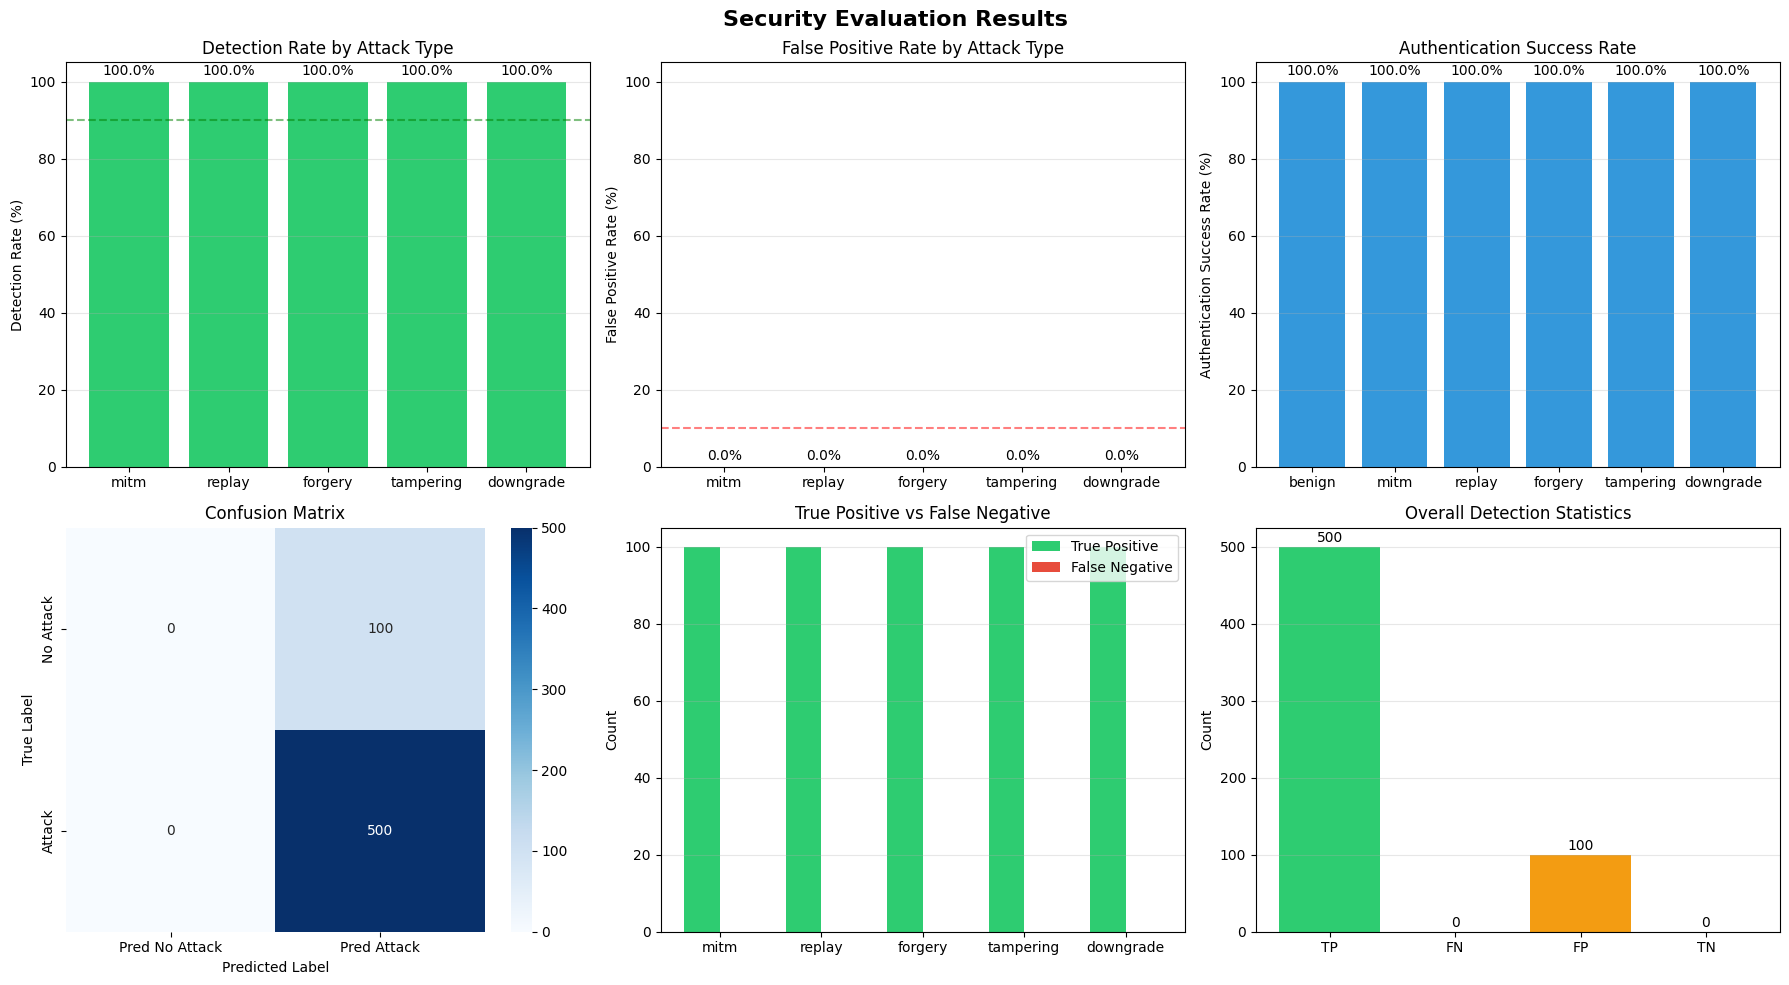


✅ Security Evaluation Complete


In [ ]:
# =============================================================================
# 7. SECURITY EVALUATION - Independent Attack Testing
#     (Using Trained Model - NO Retraining)
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from stable_baselines3 import PPO
import warnings
warnings.filterwarnings('ignore')

print("=" * 80)
print("🔐 SECURITY EVALUATION")
print("=" * 80)
print("📌 Using trained model (no retraining)")
print("📌 100 episodes per attack type + 100 benign")
print("📌 Metrics: TP, FN, FP, TN, Detection Rate, FPR, ASR")
print("=" * 80)
print()

# =============================================================================
# LOAD TRAINED MODEL
# =============================================================================

print("1. Loading trained model...")
model = PPO.load("healthcare_adaptive_tls_model_final")
print("   ✅ Model loaded")
print()

# =============================================================================
# SECURITY EVALUATION
# =============================================================================

def run_security_evaluation(model, num_episodes=100):

    attack_types = ["benign", "mitm", "replay", "forgery", "tampering", "downgrade"]

    results = {
        "attack_type": [],
        "tp": [], "fn": [], "fp": [], "tn": [],
        "detection_rate": [], "fpr": [], "asr": []
    }

    all_true = []
    all_pred = []

    for attack_type in attack_types:
        print(f"\n   Testing: {attack_type.upper()}")

        env = RealisticHealthcareIoTEnv(num_devices=15)

        tp = fn = fp = tn = 0
        successful_auth = 0

        for episode in range(num_episodes):
            obs = env.reset()
            done = False
            attack_detected = False
            auth_success = False

            while not done:
                action, _ = model.predict(obs, deterministic=True)
                if isinstance(action, np.ndarray):
                    action = action.item()
                obs, reward, done, info = env.step(action)

                if info.get("attack_detected", False):
                    attack_detected = True
                if info.get("success", False):
                    auth_success = True

            # Update confusion matrix
            if attack_type == "benign":
                if attack_detected:
                    fp += 1
                    all_pred.append("attack")
                else:
                    tn += 1
                    all_pred.append("no_attack")
                all_true.append("benign")
            else:
                if attack_detected:
                    tp += 1
                    all_pred.append("attack")
                else:
                    fn += 1
                    all_pred.append("no_attack")
                all_true.append(attack_type)

            if auth_success:
                successful_auth += 1

        # Calculate metrics
        total_attacks = tp + fn
        total_benign = fp + tn

        results["attack_type"].append(attack_type)
        results["tp"].append(tp)
        results["fn"].append(fn)
        results["fp"].append(fp)
        results["tn"].append(tn)
        results["detection_rate"].append((tp / total_attacks * 100) if total_attacks > 0 else 0)
        results["fpr"].append((fp / total_benign * 100) if total_benign > 0 else 0)
        results["asr"].append((successful_auth / num_episodes * 100))

        print(f"      TP:{tp:3d}  FN:{fn:3d}  FP:{fp:3d}  TN:{tn:3d}")
        print(f"      Detection Rate: {results['detection_rate'][-1]:.1f}%  FPR: {results['fpr'][-1]:.1f}%  ASR: {results['asr'][-1]:.1f}%")

    return pd.DataFrame(results), all_true, all_pred


# =============================================================================
# RUN
# =============================================================================

print("2. Running security evaluation...")
print("-" * 60)

df_results, true_labels, pred_labels = run_security_evaluation(model, num_episodes=100)

# =============================================================================
# RESULTS
# =============================================================================

print("\n" + "=" * 60)
print("📊 RESULTS SUMMARY")
print("=" * 60)

print("\nPer-Attack Metrics:")
print("-" * 50)
print(df_results[["attack_type", "tp", "fn", "fp", "tn", "detection_rate", "fpr", "asr"]].to_string(index=False))

# Overall
total_tp = df_results["tp"].sum()
total_fn = df_results["fn"].sum()
total_fp = df_results["fp"].sum()
total_tn = df_results["tn"].sum()

overall_dr = (total_tp / (total_tp + total_fn) * 100) if (total_tp + total_fn) > 0 else 0
overall_fpr = (total_fp / (total_fp + total_tn) * 100) if (total_fp + total_tn) > 0 else 0
overall_asr = df_results["asr"].mean()

print("\nOverall Metrics:")
print("-" * 50)
print(f"  True Positives:  {total_tp}")
print(f"  False Negatives: {total_fn}")
print(f"  False Positives: {total_fp}")
print(f"  True Negatives:  {total_tn}")
print(f"  Detection Rate:  {overall_dr:.1f}%")
print(f"  False Positive Rate: {overall_fpr:.1f}%")
print(f"  Authentication Success Rate: {overall_asr:.1f}%")

# Confusion Matrix
print("\nConfusion Matrix (Binary: Attack vs No Attack):")
print("-" * 50)
true_binary = [1 if x != "benign" else 0 for x in true_labels]
pred_binary = [1 if x == "attack" else 0 for x in pred_labels]
cm = confusion_matrix(true_binary, pred_binary)
cm_df = pd.DataFrame(cm,
                     index=["No Attack", "Attack"],
                     columns=["Pred No Attack", "Pred Attack"])
print(cm_df)

# =============================================================================
# VISUALIZATION
# =============================================================================

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Security Evaluation Results", fontsize=16, fontweight="bold")

# 1. Detection Rate
ax = axes[0, 0]
attack_types = df_results[df_results["attack_type"] != "benign"]["attack_type"]
dr = df_results[df_results["attack_type"] != "benign"]["detection_rate"]
colors = ['#2ecc71' if x >= 90 else '#f1c40f' if x >= 70 else '#e74c3c' for x in dr]
ax.bar(attack_types, dr, color=colors)
ax.set_ylabel("Detection Rate (%)")
ax.set_title("Detection Rate by Attack Type")
ax.set_ylim([0, 105])
for i, v in enumerate(dr):
    ax.text(i, v + 1, f"{v:.1f}%", ha='center', va='bottom', fontsize=10)
ax.axhline(y=90, color='green', linestyle='--', alpha=0.5)
ax.grid(True, alpha=0.3, axis='y')

# 2. FPR
ax = axes[0, 1]
fpr = df_results[df_results["attack_type"] != "benign"]["fpr"]
colors = ['#e74c3c' if x > 10 else '#2ecc71' for x in fpr]
ax.bar(attack_types, fpr, color=colors)
ax.set_ylabel("False Positive Rate (%)")
ax.set_title("False Positive Rate by Attack Type")
ax.set_ylim([0, 105])
for i, v in enumerate(fpr):
    ax.text(i, v + 1, f"{v:.1f}%", ha='center', va='bottom', fontsize=10)
ax.axhline(y=10, color='red', linestyle='--', alpha=0.5)
ax.grid(True, alpha=0.3, axis='y')

# 3. ASR
ax = axes[0, 2]
asr = df_results["asr"]
ax.bar(df_results["attack_type"], asr, color='#3498db')
ax.set_ylabel("Authentication Success Rate (%)")
ax.set_title("Authentication Success Rate")
ax.set_ylim([0, 105])
for i, v in enumerate(asr):
    ax.text(i, v + 1, f"{v:.1f}%", ha='center', va='bottom', fontsize=10)
ax.grid(True, alpha=0.3, axis='y')

# 4. Confusion Matrix Heatmap
ax = axes[1, 0]
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', ax=ax)
ax.set_title("Confusion Matrix")
ax.set_ylabel("True Label")
ax.set_xlabel("Predicted Label")

# 5. TP vs FN
ax = axes[1, 1]
tp_vals = df_results[df_results["attack_type"] != "benign"]["tp"]
fn_vals = df_results[df_results["attack_type"] != "benign"]["fn"]
x = np.arange(len(attack_types))
width = 0.35
ax.bar(x - width/2, tp_vals, width, label='True Positive', color='#2ecc71')
ax.bar(x + width/2, fn_vals, width, label='False Negative', color='#e74c3c')
ax.set_xticks(x)
ax.set_xticklabels(attack_types)
ax.set_ylabel("Count")
ax.set_title("True Positive vs False Negative")
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

# 6. Overall Summary
ax = axes[1, 2]
metrics = {"TP": total_tp, "FN": total_fn, "FP": total_fp, "TN": total_tn}
colors = ['#2ecc71', '#e74c3c', '#f39c12', '#3498db']
ax.bar(metrics.keys(), metrics.values(), color=colors)
ax.set_ylabel("Count")
ax.set_title("Overall Detection Statistics")
for i, (k, v) in enumerate(metrics.items()):
    ax.text(i, v + 2, str(v), ha='center', va='bottom', fontsize=10)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("\n" + "=" * 80)
print("✅ Security Evaluation Complete")
print("=" * 80)